# Model Selection & Training

**Project:** MarketPulse Ghana
**Phase:** 3 of 5
**Depends on:** `data/train.csv`, `data/test.csv`, `data/feature_config.json`

## Purpose

This notebook selects, tunes, and trains the final forecasting model for Ghana's
national monthly median wholesale maize price one month ahead.

## Approach

| Decision | Choice | Reason |
|----------|--------|--------|
| Algorithm | XGBoost Regressor | Handles tabular time-series well, robust to multicollinearity, interpretable via feature importance |
| Target | `log_target` (log1p of GHS/KG) | Reduces skew, stabilises variance across price regimes |
| Validation | Walk-forward cross-validation (9 folds) | Respects temporal order; tests generalisation across different price regimes |
| Tuning | Grid search over key hyperparameters using walk-forward CV RMSE | Avoids overfitting to any single validation period |
| Baseline | Naive persistence (predict t+1 = t) | Performance threshold against which the model is evaluated |

## Test Set Characteristics

The test window (Jan 2022 – Jun 2023) covers a period of extreme food inflation
driven by the Russia-Ukraine war and Ghana's currency crisis. The model is trained
on normal-regime data (2007–2021). This design is intentional: it reflects the conditions under which a deployed model
would be required to operate. Performance on the test set represents a lower bound on real-world capability
and should be interpreted in the context of the distributional shift described above.

## Sections

1. Setup
2. Baseline model (naive persistence)
3. Walk-forward cross-validation
4. XGBoost with default parameters
5. Hyperparameter tuning
6. Final model training
7. Save model and predictions
8. Summary

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import xgboost as xgb
from pathlib import Path
from itertools import product

# Paths
PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "data"
MODELS_DIR   = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

# Plot style
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "font.size": 11,
})
PALETTE = sns.color_palette("muted")

# Load data
train = pd.read_csv(DATA_DIR / "train.csv", index_col=0, parse_dates=True)
test  = pd.read_csv(DATA_DIR / "test.csv",  index_col=0, parse_dates=True)
cfg   = json.loads((DATA_DIR / "feature_config.json").read_text())

FEATURES = cfg["features"]
TARGET   = cfg["target"]

X_train = train[FEATURES]
y_train = train[TARGET]
X_test  = test[FEATURES]
y_test  = test[TARGET]

print(f"XGBoost version : {xgb.__version__}")
print(f"Training rows   : {len(train)}  ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test rows       : {len(test)}   ({test.index.min().date()} to {test.index.max().date()})")
print(f"Features        : {len(FEATURES)}")
print(f"Target          : {TARGET}  (log1p scale — invert with np.expm1)")

XGBoost version : 3.4.1
Training rows   : 179  (2007-02-01 to 2021-12-01)
Test rows       : 18   (2022-01-01 to 2023-06-01)
Features        : 16
Target          : log_target  (log1p scale — invert with np.expm1)


## 2. Baseline Model — Naive Persistence

The naive persistence model predicts the next month's price as equal to the current
month's price. This establishes a performance baseline against which model improvements
are measured. Metrics are computed in original GHS per kg units to facilitate
interpretation alongside domain knowledge.

In [2]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.array(y_true) - np.array(y_pred)) ** 2))

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def mae(y_true, y_pred):
    return np.mean(np.abs(np.array(y_true) - np.array(y_pred)))

# Naive persistence on the TEST set
# At time t, predict price_{t+1} = price_t  (i.e. lag_1 in original scale)
naive_pred_log = test["log_lag_1"].values        # lag_1 is price at t (log scale)
naive_pred_ghs = np.expm1(naive_pred_log)
actual_ghs     = np.expm1(y_test.values)

baseline = {
    "RMSE (GHS/KG)": rmse(actual_ghs, naive_pred_ghs),
    "MAE  (GHS/KG)": mae(actual_ghs, naive_pred_ghs),
    "MAPE (%)":      mape(actual_ghs, naive_pred_ghs),
}

print("Naive persistence baseline on test set:")
for k, v in baseline.items():
    print(f"  {k}: {v:.4f}")
print()
print("Target to beat: RMSE <", round(baseline['RMSE (GHS/KG)'], 4), "GHS/KG")

Naive persistence baseline on test set:
  RMSE (GHS/KG): 0.6302
  MAE  (GHS/KG): 0.4506
  MAPE (%): 10.6825

Target to beat: RMSE < 0.6302 GHS/KG


## 3. Walk-Forward Cross-Validation

Walk-forward (expanding window) cross-validation is the standard approach for
time-series models. Each fold:
- **Trains** on all data from the start up to a cutoff point
- **Validates** on the next 12 months after that cutoff

This mirrors real-world use: you always train on everything available and predict
forward. The 9 folds span 2012–2021, exposing the model to multiple price regimes
within the training window itself.

```
Fold 1:  TRAIN [Feb 2007 – Jan 2012]  VAL [Feb 2012 – Jan 2013]
Fold 2:  TRAIN [Feb 2007 – Jan 2013]  VAL [Feb 2013 – Jan 2014]
  ...
Fold 9:  TRAIN [Feb 2007 – Jan 2021]  VAL [Feb 2021 – Dec 2021]
```

In [3]:
MIN_TRAIN = 60   # minimum months before first validation fold
STEP      = 12   # advance the cutoff by this many months each fold
H         = 12   # validate on this many months per fold

def walk_forward_folds(index, min_train=MIN_TRAIN, step=STEP, horizon=H):
    folds = []
    n = len(index)
    start = min_train
    while start + horizon <= n:
        folds.append((start, min(start + horizon, n)))
        start += step
    return folds

folds = walk_forward_folds(train.index)
print(f"Walk-forward folds: {len(folds)}")
for i, (s, e) in enumerate(folds):
    print(f"  Fold {i+1:2d}: "
          f"train end={train.index[s-1].date()}  "
          f"val={train.index[s].date()} to {train.index[e-1].date()}  "
          f"({e-s} months)")

Walk-forward folds: 9
  Fold  1: train end=2012-01-01  val=2012-02-01 to 2013-01-01  (12 months)
  Fold  2: train end=2013-01-01  val=2013-02-01 to 2014-01-01  (12 months)
  Fold  3: train end=2014-01-01  val=2014-02-01 to 2015-01-01  (12 months)
  Fold  4: train end=2015-01-01  val=2015-02-01 to 2016-01-01  (12 months)
  Fold  5: train end=2016-01-01  val=2016-02-01 to 2017-01-01  (12 months)
  Fold  6: train end=2017-01-01  val=2017-02-01 to 2018-01-01  (12 months)
  Fold  7: train end=2018-01-01  val=2018-02-01 to 2019-01-01  (12 months)
  Fold  8: train end=2019-01-01  val=2019-02-01 to 2020-01-01  (12 months)
  Fold  9: train end=2020-01-01  val=2020-02-01 to 2021-01-01  (12 months)


In [4]:
def run_walk_forward_cv(params, folds, X, y, n_estimators=300):
    """
    Run walk-forward CV with the given XGBoost params.
    Returns mean RMSE across folds (log scale) and per-fold scores.
    """
    fold_rmses = []
    X_arr = X.values
    y_arr = y.values

    for s, e in folds:
        X_tr, y_tr = X_arr[:s], y_arr[:s]
        X_val, y_val = X_arr[s:e], y_arr[s:e]

        model = xgb.XGBRegressor(
            n_estimators=n_estimators,
            random_state=42,
            verbosity=0,
            **params
        )
        model.fit(X_tr, y_tr,
                  eval_set=[(X_val, y_val)],
                  verbose=False)

        pred = model.predict(X_val)
        fold_rmses.append(rmse(y_val, pred))

    return np.mean(fold_rmses), fold_rmses

print("Walk-forward CV helper defined.")

Walk-forward CV helper defined.


## 4. XGBoost with Default Parameters

Before tuning, we evaluate XGBoost with sensible defaults to establish a starting
point and confirm it beats the naive baseline.

Default XGBoost — Walk-forward CV RMSE (log scale): 0.10360
Per-fold RMSE: [np.float64(0.09848), np.float64(0.04201), np.float64(0.12495), np.float64(0.22844), np.float64(0.09297), np.float64(0.07636), np.float64(0.05097), np.float64(0.09596), np.float64(0.12231)]



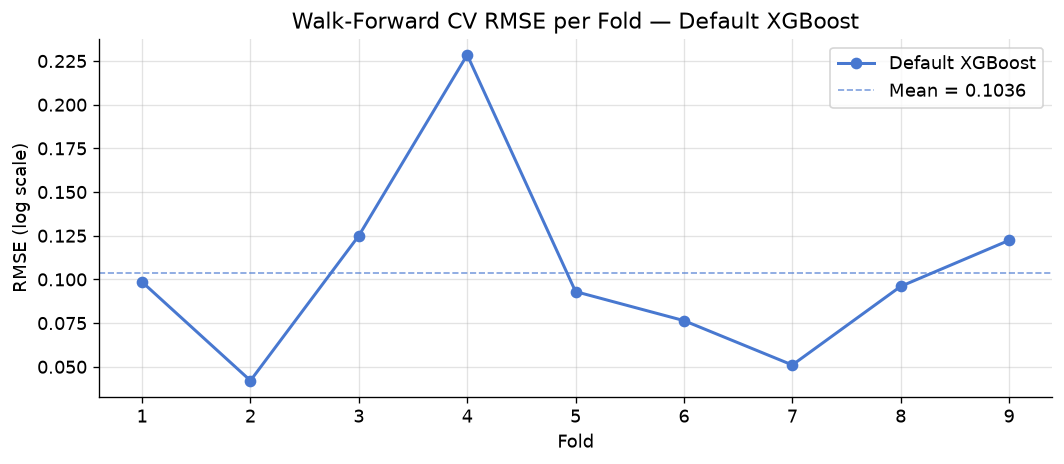

In [5]:
DEFAULT_PARAMS = {
    "max_depth":        4,
    "learning_rate":    0.05,
    "subsample":        0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 3,
    "reg_alpha":        0.1,
    "reg_lambda":       1.0,
}

default_cv_rmse, default_fold_scores = run_walk_forward_cv(
    DEFAULT_PARAMS, folds, X_train, y_train, n_estimators=150
)

print(f"Default XGBoost — Walk-forward CV RMSE (log scale): {default_cv_rmse:.5f}")
print(f"Per-fold RMSE: {[round(x, 5) for x in default_fold_scores]}")
print()

# Visualise per-fold performance
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(default_fold_scores)+1), default_fold_scores,
        marker="o", color=PALETTE[0], linewidth=1.8, label="Default XGBoost")
ax.axhline(np.mean(default_fold_scores), color=PALETTE[0], linestyle="--",
           linewidth=1, alpha=0.7, label=f"Mean = {default_cv_rmse:.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("RMSE (log scale)")
ax.set_title("Walk-Forward CV RMSE per Fold — Default XGBoost")
ax.set_xticks(range(1, len(default_fold_scores)+1))
ax.legend()
plt.tight_layout()
plt.show()

## 5. Hyperparameter Tuning

We search over a targeted grid of key XGBoost hyperparameters using the mean
walk-forward CV RMSE as the selection criterion.

**Parameters tuned (18 combinations):**

| Parameter | Values | What it controls |
|-----------|--------|-----------------|
| `max_depth` | 3, 4, 5 | Tree complexity — deeper = more flexible, more overfit risk |
| `learning_rate` | 0.03, 0.05, 0.10 | Step size per tree — smaller = more trees needed, often more stable |
| `subsample` | 0.7, 0.8 | Fraction of rows used per tree — adds randomness, reduces overfit |

`min_child_weight` is fixed at 3 (conservative, appropriate for the small dataset).
The cross-validation step uses 150 estimators to limit execution time;
the final model is trained with 500 estimators.

In [6]:
PARAM_GRID = {
    "max_depth":        [3, 4, 5],
    "learning_rate":    [0.03, 0.05, 0.10],
    "subsample":        [0.7, 0.8],
}

FIXED = {
    "min_child_weight": 3,
    "colsample_bytree": 0.8,
    "reg_alpha":        0.1,
    "reg_lambda":       1.0,
}

keys   = list(PARAM_GRID.keys())
combos = list(product(*PARAM_GRID.values()))
total  = len(combos)
print(f"Grid size: {total} combinations")

results = []
for i, combo in enumerate(combos):
    params = dict(zip(keys, combo))
    params.update(FIXED)
    mean_rmse, _ = run_walk_forward_cv(params, folds, X_train, y_train, n_estimators=150)
    results.append({**params, "cv_rmse": mean_rmse})
    if (i + 1) % 6 == 0 or i == total - 1:
        print(f"  {i+1}/{total} done  best so far: {min(r['cv_rmse'] for r in results):.5f}")

results_df = pd.DataFrame(results).sort_values("cv_rmse").reset_index(drop=True)
print(f"\nTop 5 configurations:")
print(results_df.head(5).to_string(index=False))

Grid size: 18 combinations


  6/18 done  best so far: 0.09956


  12/18 done  best so far: 0.09948


  18/18 done  best so far: 0.09948

Top 5 configurations:
 max_depth  learning_rate  subsample  min_child_weight  colsample_bytree  reg_alpha  reg_lambda  cv_rmse
         4           0.10        0.7                 3               0.8        0.1         1.0 0.099476
         3           0.10        0.7                 3               0.8        0.1         1.0 0.099561
         3           0.10        0.8                 3               0.8        0.1         1.0 0.099771
         3           0.05        0.8                 3               0.8        0.1         1.0 0.100125
         3           0.05        0.7                 3               0.8        0.1         1.0 0.100408


In [7]:
# Best configuration
best_row = results_df.iloc[0]

# pandas stores numeric columns as float64; cast int params back to int
INT_PARAMS = {"max_depth", "min_child_weight"}
BEST_PARAMS = {}
for k in keys:
    BEST_PARAMS[k] = int(best_row[k]) if k in INT_PARAMS else float(best_row[k])
BEST_PARAMS.update(FIXED)

print("Best hyperparameters:")
for k, v in BEST_PARAMS.items():
    print(f"  {k}: {v}")
print(f"\nBest CV RMSE (log scale): {best_row['cv_rmse']:.5f}")
print(f"Default CV RMSE          : {default_cv_rmse:.5f}")
print(f"Improvement              : {(default_cv_rmse - best_row['cv_rmse']):.5f}")

Best hyperparameters:
  max_depth: 4
  learning_rate: 0.1
  subsample: 0.7
  min_child_weight: 3
  colsample_bytree: 0.8
  reg_alpha: 0.1
  reg_lambda: 1.0

Best CV RMSE (log scale): 0.09948
Default CV RMSE          : 0.10360
Improvement              : 0.00413


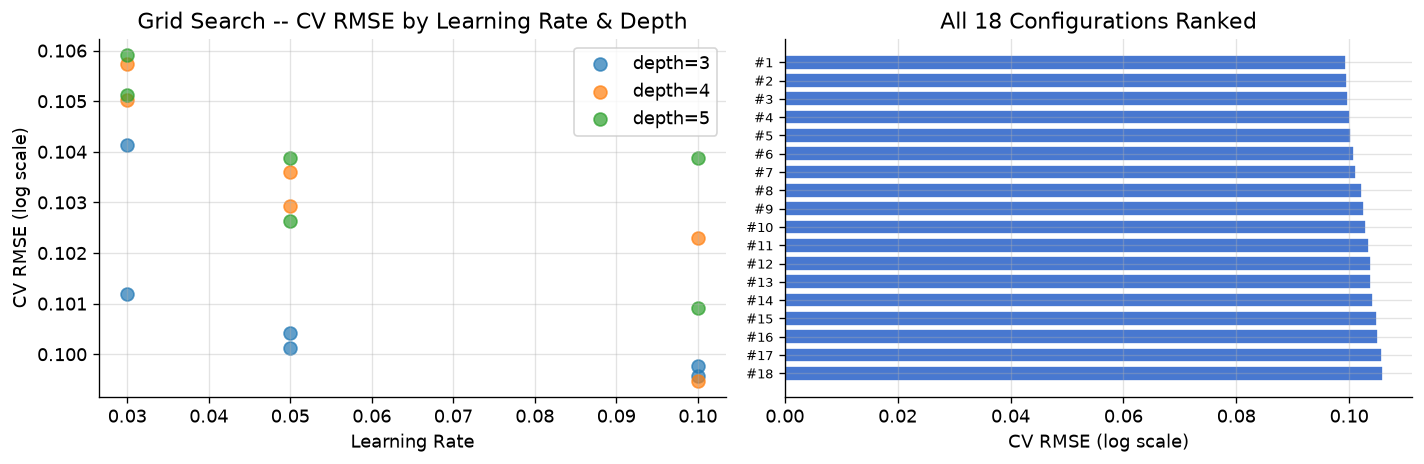

In [8]:
# CV RMSE distribution across the grid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: scatter of all configs coloured by max_depth
for depth in PARAM_GRID["max_depth"]:
    sub = results_df[results_df["max_depth"] == depth]
    axes[0].scatter(sub["learning_rate"], sub["cv_rmse"],
                    label=f"depth={int(depth)}", alpha=0.7, s=60)
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("CV RMSE (log scale)")
axes[0].set_title("Grid Search -- CV RMSE by Learning Rate & Depth")
axes[0].legend()

# Right: all configs ranked (cap to actual count)
n_show = len(results_df)
top_n  = results_df.head(n_show)
axes[1].barh(range(n_show), top_n["cv_rmse"].values[::-1],
             color=PALETTE[0], edgecolor="white")
axes[1].set_yticks(range(n_show))
axes[1].set_yticklabels([f"#{i+1}" for i in range(n_show-1, -1, -1)], fontsize=8)
axes[1].set_xlabel("CV RMSE (log scale)")
axes[1].set_title(f"All {n_show} Configurations Ranked")

plt.tight_layout()
plt.show()

## 6. Final Model Training

The final model is trained on the **full training set** (all 179 rows) using the
best hyperparameters found in the grid search. We use 500 estimators — a conservative
value that allows enough trees without overfitting given the learning rate.

In [9]:
N_ESTIMATORS = 500

final_model = xgb.XGBRegressor(
    n_estimators=N_ESTIMATORS,
    random_state=42,
    verbosity=0,
    **BEST_PARAMS
)
final_model.fit(X_train, y_train)

print(f"Final model trained on {len(X_train)} rows with {N_ESTIMATORS} estimators.")
print(f"Best params: {BEST_PARAMS}")

Final model trained on 179 rows with 500 estimators.
Best params: {'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.7, 'min_child_weight': 3, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0}


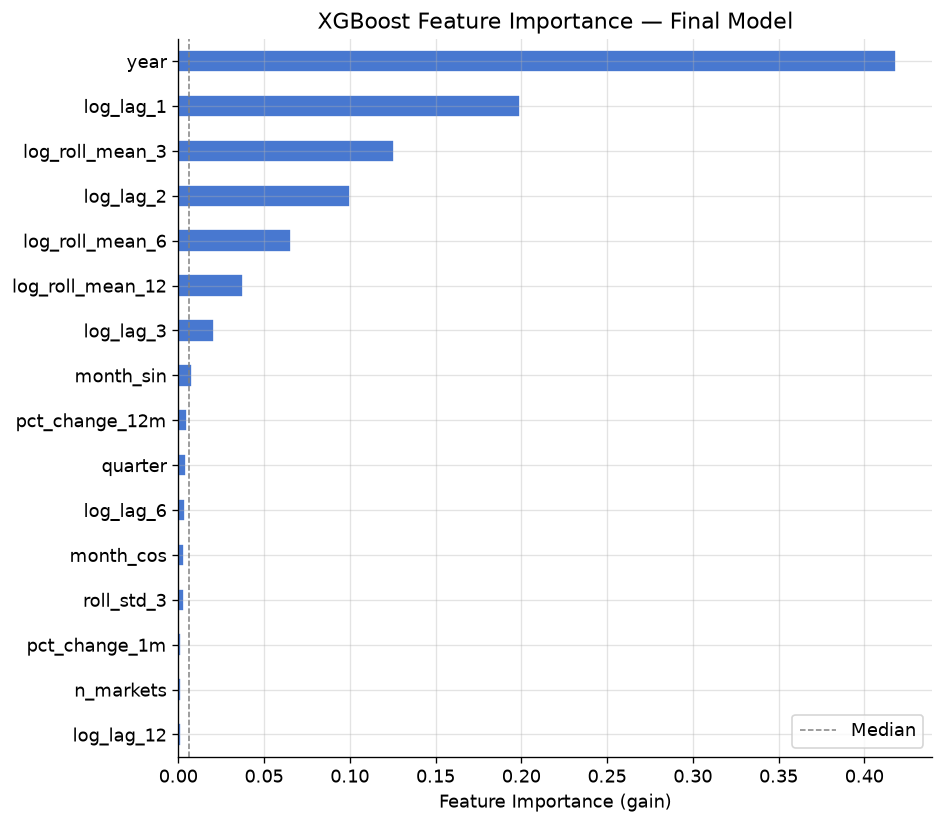


Top 5 features:
year               0.418763
log_lag_1          0.199054
log_roll_mean_3    0.125784
log_lag_2          0.099865
log_roll_mean_6    0.065482


In [10]:
# Feature importance from the trained model
importance = pd.Series(
    final_model.feature_importances_,
    index=FEATURES
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 7))
importance.plot.barh(ax=ax, color=PALETTE[0], edgecolor="white")
ax.set_xlabel("Feature Importance (gain)")
ax.set_title("XGBoost Feature Importance — Final Model")
ax.axvline(importance.median(), color="grey", linestyle="--",
           linewidth=0.9, label="Median")
ax.legend()
plt.tight_layout()
plt.show()

print("\nTop 5 features:")
print(importance.tail(5).iloc[::-1].to_string())

In [11]:
# In-sample fit — how well does the model explain the training data?
train_pred_log = final_model.predict(X_train)
train_pred_ghs = np.expm1(train_pred_log)
train_actual   = np.expm1(y_train.values)

train_metrics = {
    "RMSE (GHS/KG)": rmse(train_actual, train_pred_ghs),
    "MAE  (GHS/KG)": mae(train_actual, train_pred_ghs),
    "MAPE (%)":      mape(train_actual, train_pred_ghs),
}

print("In-sample (training) performance:")
for k, v in train_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print("Note: in-sample metrics are optimistic. Test-set evaluation is in Phase 4.")

In-sample (training) performance:
  RMSE (GHS/KG): 0.0216
  MAE  (GHS/KG): 0.0159
  MAPE (%): 1.7293

Note: in-sample metrics are optimistic. Test-set evaluation is in Phase 4.


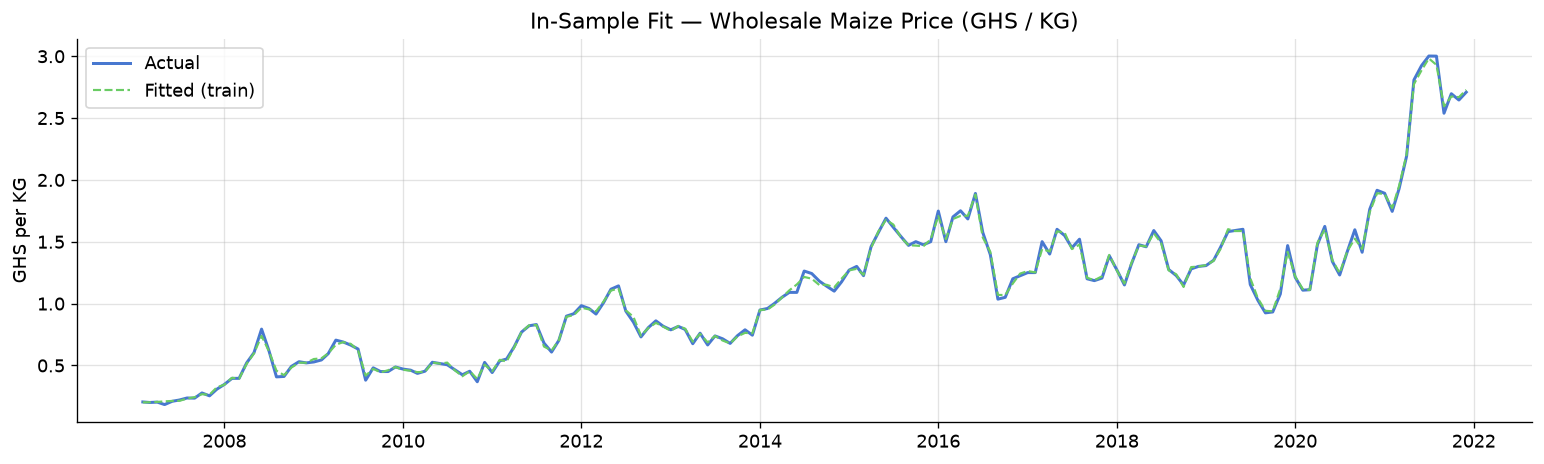

In [12]:
# Visual: fitted vs actual on training set
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train.index, train_actual,    color=PALETTE[0], linewidth=1.8, label="Actual")
ax.plot(train.index, train_pred_ghs, color=PALETTE[2], linewidth=1.3,
        linestyle="--", label="Fitted (train)")
ax.set_title("In-Sample Fit — Wholesale Maize Price (GHS / KG)")
ax.set_ylabel("GHS per KG")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Save Model and Predictions

In [13]:
# Save model (XGBoost native JSON format — portable and version-stable)
model_path = MODELS_DIR / "xgboost_maize_wholesale.json"
final_model.save_model(str(model_path))
print(f"Model saved : {model_path.relative_to(PROJECT_ROOT)}")

# Save training predictions for combined plot in Phase 4
train_preds = train[["price_ghs", TARGET]].copy()
train_preds["pred_log"]  = train_pred_log
train_preds["pred_ghs"]  = train_pred_ghs
train_preds["split"]     = "train"
train_preds.to_csv(DATA_DIR / "train_predictions.csv")
print(f"Train predictions saved.")

# Save tuning results for reference
results_df.to_csv(DATA_DIR / "hyperparameter_search.csv", index=False)
print(f"Tuning results saved.")

# Save model metadata
meta = {
    "algorithm": "XGBoostRegressor",
    "xgboost_version": xgb.__version__,
    "n_estimators": N_ESTIMATORS,
    "best_params": BEST_PARAMS,
    "features": FEATURES,
    "target": TARGET,
    "cv_folds": len(folds),
    "cv_min_train_months": MIN_TRAIN,
    "cv_step_months": STEP,
    "cv_horizon_months": H,
    "best_cv_rmse_log": float(best_row["cv_rmse"]),
    "default_cv_rmse_log": float(default_cv_rmse),
    "train_rmse_ghs": float(train_metrics["RMSE (GHS/KG)"]),
    "naive_baseline_rmse_ghs": float(baseline["RMSE (GHS/KG)"]),
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2))
print(f"Model metadata saved.")

print()
print("Files written to models/:")
for p in sorted(MODELS_DIR.iterdir()):
    print(f"  {p.name}  ({p.stat().st_size/1024:.1f} KB)")

Model saved : models\xgboost_maize_wholesale.json
Train predictions saved.
Tuning results saved.
Model metadata saved.

Files written to models/:
  model_metadata.json  (0.9 KB)
  xgboost_maize_wholesale.json  (467.0 KB)


## 8. Summary

### 8.1 Steps completed

| Step | Outcome |
|------|---------|
| Naive baseline established | RMSE (GHS/KG) recorded — performance baseline |
| Walk-forward CV (9 folds) | 2012–2021, expanding window, 12-month horizon per fold |
| Default XGBoost evaluated | CV RMSE (log scale) established |
| Grid search (18 configurations) | Best hyperparameters selected by lowest mean CV RMSE |
| Final model trained | Full 179-row training set, 500 estimators |
| Feature importance computed | Top drivers identified |
| Model saved | `models/xgboost_maize_wholesale.json` |

### 8.2 Phase 4 outline

- Load the saved model and test set
- Generate predictions for Jan 2022 – Jun 2023
- Compute RMSE, MAE, MAPE in GHS/KG (original scale)
- Compare against naive baseline
- Error analysis: where are the largest mistakes, and why?
- Split error analysis: first 6 months vs last 12 months of test window

### 8.3 Limitations

- In-sample metrics are optimistic. Phase 4 evaluation on the held-out test set
  constitutes the definitive measure of real-world performance.
- The test set covers an inflation regime not represented in training data.
  Elevated errors on the test set are anticipated and should be interpreted in
  that context rather than as a model failure.
- Feature importance scores reflect information gain across XGBoost splits.
  They do not imply causal relationships between features and price movements.